# PrédiMaint — Exploration des données

**Objectif de ce notebook** (livrable L2 du cahier des charges) : comprendre les données des capteurs de l'atelier d'usinage avant de construire le modèle de prédiction.

Questions auxquelles on répond :
1. Combien de pannes, et de quels types ?
2. Quelles gammes de produits tombent le plus en panne ?
3. Comment se comportent les capteurs juste avant une panne ?
4. Les règles de panne décrites dans la documentation se vérifient-elles sur les données ? (fonction F3)
5. Quelles décisions en tirer pour le modèle ?

**Données** : AI4I 2020 Predictive Maintenance Dataset — UCI Machine Learning Repository, S. Matzka (2020), DOI 10.24432/C5HS5C, licence CC BY 4.0. Jeu de données **synthétique** qui reproduit des données industrielles réelles.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd().parent            # le notebook est dans notebooks/
FIG = ROOT / "docs" / "figures"     # figures réutilisées dans le README
BLEU, ROUGE, GRIS = "#1f4e79", "#c0392b", "#9aa5b1"

def sauver(nom):
    plt.savefig(FIG / f"{nom}.png", bbox_inches="tight")

Matplotlib is building the font cache; this may take a moment.


## 1. Chargement et premier contrôle

In [2]:
df = pd.read_csv(ROOT / "data" / "raw" / "ai4i2020.csv")
print(f"{df.shape[0]} lignes, {df.shape[1]} colonnes")
print(f"Valeurs manquantes : {df.isna().sum().sum()}  |  Lignes en double : {df.duplicated().sum()}")
df.head()

10000 lignes, 14 colonnes
Valeurs manquantes : 0  |  Lignes en double : 0


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
# Noms de colonnes plus courts et en français, pour la lisibilité
df = df.rename(columns={
    "Product ID": "id_produit", "Type": "gamme",
    "Air temperature [K]": "temp_air", "Process temperature [K]": "temp_process",
    "Rotational speed [rpm]": "vitesse", "Torque [Nm]": "couple",
    "Tool wear [min]": "usure_outil", "Machine failure": "panne",
})
CAPTEURS = ["temp_air", "temp_process", "vitesse", "couple", "usure_outil"]
MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]
NOMS_MODES = {"TWF": "Usure de l'outil", "HDF": "Dissipation de chaleur", "PWF": "Puissance",
              "OSF": "Surcharge", "RNF": "Aléatoire"}
df[CAPTEURS].describe().round(1)

,temp_air,temp_process,vitesse,couple,usure_outil
count,10000.0,10000.0,10000.0,10000.0,10000.0
mean,300.0,310.0,1538.8,40.0,108.0
std,2.0,1.5,179.3,10.0,63.7
min,295.3,305.7,1168.0,3.8,0.0
25%,298.3,308.8,1423.0,33.2,53.0
50%,300.1,310.1,1503.0,40.1,108.0
75%,301.5,311.1,1612.0,46.8,162.0
max,304.5,313.8,2886.0,76.6,253.0


**Lecture** : les températures varient peu (environ ±2 K autour de 300 K pour l'air, 310 K pour le procédé). La vitesse de rotation va de 1 168 à 2 886 tr/min, le couple de 3,8 à 76,6 N·m, et l'usure de l'outil de 0 à 253 minutes. Aucune valeur manquante ni doublon : le fichier est propre.

## 2. La variable à prédire : panne ou pas panne

Pannes : 339 sur 10000 relevés, soit 3.39%


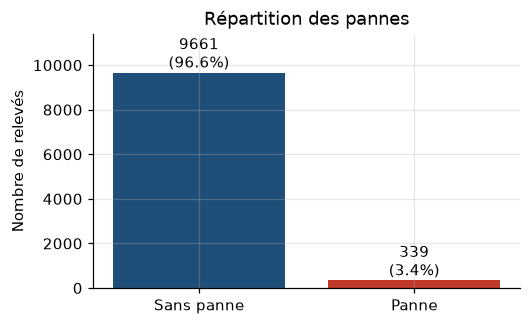

In [4]:
taux = df["panne"].mean()
print(f"Pannes : {df['panne'].sum()} sur {len(df)} relevés, soit {taux:.2%}")

fig, ax = plt.subplots(figsize=(5, 3))
comptes = df["panne"].value_counts().sort_index()
ax.bar(["Sans panne", "Panne"], comptes.values, color=[BLEU, ROUGE])
for i, v in enumerate(comptes.values):
    ax.text(i, v, f"{v}\n({v/len(df):.1%})", ha="center", va="bottom")
ax.set_ylabel("Nombre de relevés"); ax.set_title("Répartition des pannes")
ax.set_ylim(0, comptes.max() * 1.18)
sauver("01_repartition_pannes"); plt.show()

**Constat majeur : les données sont très déséquilibrées.** Seuls 3,4 % des relevés correspondent à une panne. Un modèle « paresseux » qui répondrait toujours *pas de panne* aurait 96,6 % de bonnes réponses… tout en ne détectant aucune panne. C'est pourquoi le cahier des charges évalue le modèle sur le **rappel** (part des pannes détectées) et la **précision** (part des alertes justifiées), et non sur le taux de bonnes réponses.

## 3. Les types de panne

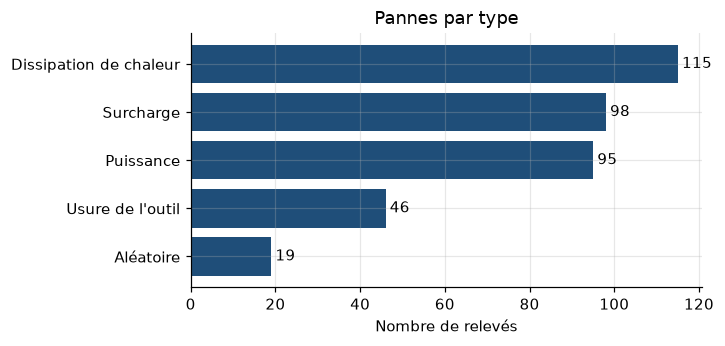

Relevés avec plusieurs types de panne à la fois : 24
Pannes sans aucun type indiqué               : 9
Type indiqué mais panne = 0                  : 18 → tous de type RNF


In [5]:
nb_modes = df[MODES].sum(axis=1)
comptes_modes = df[MODES].sum().rename(index=NOMS_MODES).sort_values()

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(comptes_modes.index, comptes_modes.values, color=BLEU)
for i, v in enumerate(comptes_modes.values):
    ax.text(v + 1, i, str(v), va="center")
ax.set_xlabel("Nombre de relevés"); ax.set_title("Pannes par type")
sauver("02_pannes_par_type"); plt.show()

print("Relevés avec plusieurs types de panne à la fois :", (nb_modes > 1).sum())
print("Pannes sans aucun type indiqué               :", ((df["panne"] == 1) & (nb_modes == 0)).sum())
print("Type indiqué mais panne = 0                  :", ((df["panne"] == 0) & (nb_modes > 0)).sum(),
      "→ tous de type", df.loc[(df["panne"] == 0) & (nb_modes > 0), MODES].sum().idxmax())

**Lecture** :
- Les pannes les plus fréquentes sont la **dissipation de chaleur** (115), la **surcharge** (98) et la **puissance** (95).
- Le fichier contient **46 pannes d'usure** et **19 pannes aléatoires**. La documentation annonçait 120 et 5 : elle compte aussi les changements d'outil sans panne. On se fie au fichier.
- **24 relevés cumulent plusieurs types** de panne.
- **Deux incohérences** à traiter :
  - 9 pannes n'ont aucun type indiqué ;
  - 18 pannes « aléatoires » ne sont pas comptées comme pannes (`panne = 0`).

  Décision pour la suite : la variable `panne` reste la référence pour le modèle principal. Pour le type de panne, les 9 pannes sans type seront classées « Indéterminé ».

## 4. Les gammes de produits (L, M, H)

,releves,pannes,taux
gamme,,,
L,6000,235,3.92 %
M,2997,83,2.77 %
H,1003,21,2.09 %


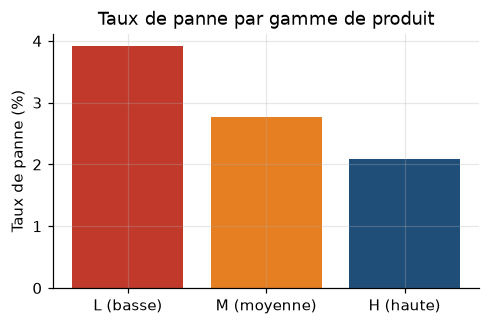

In [6]:
par_gamme = df.groupby("gamme").agg(releves=("panne", "size"), pannes=("panne", "sum"),
                                    taux=("panne", "mean")).loc[["L", "M", "H"]]
display(par_gamme.assign(taux=lambda t: (t.taux * 100).round(2).astype(str) + " %"))

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(["L (basse)", "M (moyenne)", "H (haute)"], par_gamme["taux"] * 100, color=[ROUGE, "#e67e22", BLEU])
ax.set_ylabel("Taux de panne (%)"); ax.set_title("Taux de panne par gamme de produit")
sauver("03_taux_par_gamme"); plt.show()

**Lecture** : la gamme **L** représente 60 % de la production et tombe presque **deux fois plus souvent** en panne (3,9 %) que la gamme **H** (2,1 %). C'est cohérent avec la documentation : la limite de surcharge est plus basse pour les produits L (11 000 min·N·m) que pour les produits H (13 000). La gamme sera donc une variable d'entrée du modèle.

## 5. Les capteurs : que se passe-t-il avant une panne ?

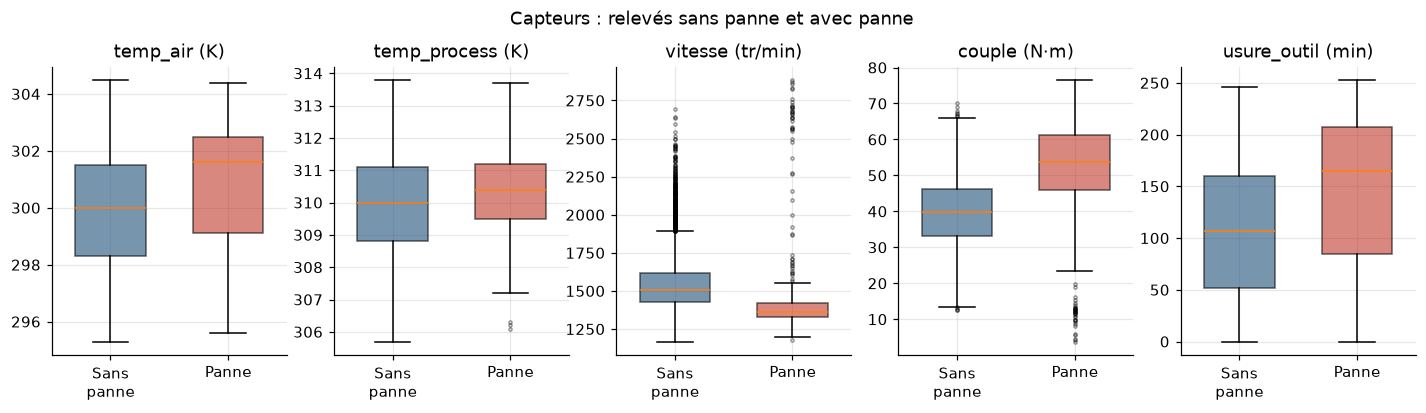

,temp_air,temp_process,vitesse,couple,usure_outil
panne,,,,,
Sans panne,300.0,310.0,1540.3,39.6,106.7
Panne,300.9,310.3,1496.5,50.2,143.8


In [7]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
unites = {"temp_air": "K", "temp_process": "K", "vitesse": "tr/min", "couple": "N·m", "usure_outil": "min"}
for ax, c in zip(axes, CAPTEURS):
    data = [df.loc[df.panne == 0, c], df.loc[df.panne == 1, c]]
    b = ax.boxplot(data, tick_labels=["Sans\npanne", "Panne"], patch_artist=True, widths=0.6,
                   flierprops={"markersize": 2, "alpha": 0.4})
    for patch, col in zip(b["boxes"], [BLEU, ROUGE]):
        patch.set_facecolor(col); patch.set_alpha(0.6)
    ax.set_title(f"{c} ({unites[c]})")
fig.suptitle("Capteurs : relevés sans panne et avec panne", y=1.03)
sauver("04_capteurs_panne"); plt.show()

df.groupby("panne")[CAPTEURS].mean().round(1).rename(index={0: "Sans panne", 1: "Panne"})

**Lecture** :
- **Couple** : nettement plus élevé en cas de panne (environ 50 N·m contre 40 N·m en moyenne), avec aussi quelques pannes à couple très faible.
- **Usure de l'outil** : plus élevée en cas de panne (144 min contre 107 min en moyenne).
- **Vitesse** : la plupart des pannes surviennent à vitesse basse (médiane d'environ 1 360 tr/min contre 1 500 sans panne) ; quelques-unes, à très haute vitesse, correspondent aux pannes de puissance.
- **Températures** : la différence est faible si l'on regarde chaque capteur seul. C'est l'**écart** entre les deux températures qui compte (section 6).

Aucun capteur ne suffit seul à prédire la panne : ce sont les **combinaisons** de mesures qui l'expliquent. D'où l'intérêt de créer des variables dérivées.

## 6. Variables dérivées (fonction F6)

À partir de la physique de l'usinage, on crée trois variables :

| Variable | Calcul | Lien avec une panne |
|---|---|---|
| `ecart_temp` | température du procédé − température de l'air (K) | Dissipation de chaleur (HDF) |
| `puissance` | couple × vitesse × 2π / 60 (W) | Puissance (PWF) |
| `contrainte` | usure de l'outil × couple (min·N·m) | Surcharge (OSF) |

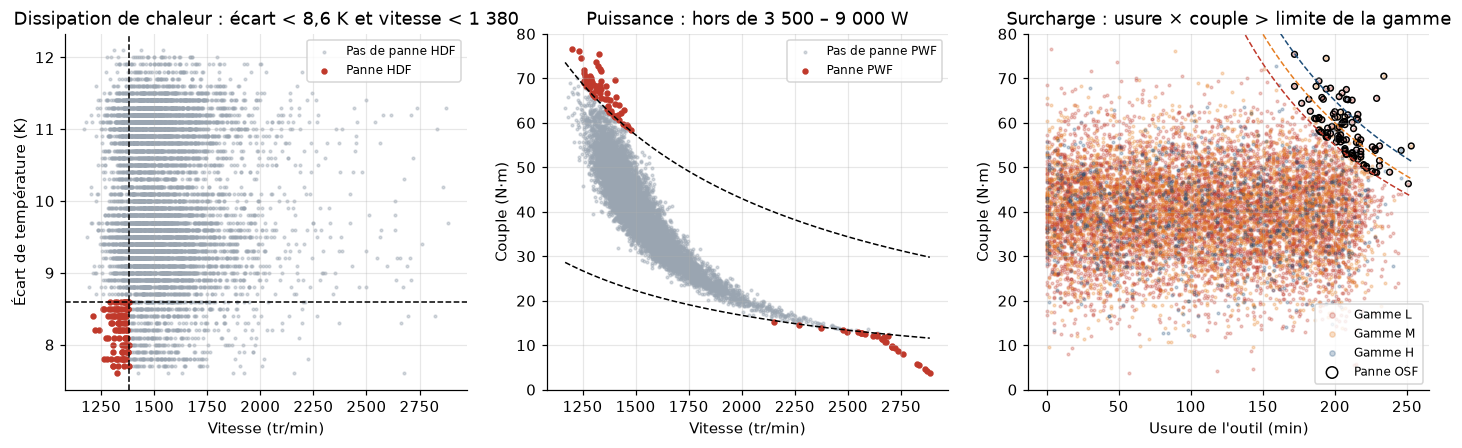

In [8]:
df["ecart_temp"] = df["temp_process"] - df["temp_air"]
df["puissance"] = df["couple"] * df["vitesse"] * 2 * np.pi / 60
df["contrainte"] = df["usure_outil"] * df["couple"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

ax = axes[0]
ok, hdf = df[df.HDF == 0], df[df.HDF == 1]
ax.scatter(ok.vitesse, ok.ecart_temp, s=3, c=GRIS, alpha=0.4, label="Pas de panne HDF")
ax.scatter(hdf.vitesse, hdf.ecart_temp, s=10, c=ROUGE, label="Panne HDF")
ax.axhline(8.6, ls="--", c="k", lw=1); ax.axvline(1380, ls="--", c="k", lw=1)
ax.set_xlabel("Vitesse (tr/min)"); ax.set_ylabel("Écart de température (K)")
ax.set_title("Dissipation de chaleur : écart < 8,6 K et vitesse < 1 380"); ax.legend(fontsize=8)

ax = axes[1]
ok, pwf = df[df.PWF == 0], df[df.PWF == 1]
ax.scatter(ok.vitesse, ok.couple, s=3, c=GRIS, alpha=0.4, label="Pas de panne PWF")
ax.scatter(pwf.vitesse, pwf.couple, s=10, c=ROUGE, label="Panne PWF")
v = np.linspace(df.vitesse.min(), df.vitesse.max(), 200)
for p in (3500, 9000):
    ax.plot(v, p / (v * 2 * np.pi / 60), "k--", lw=1)
ax.set_ylim(0, 80)
ax.set_xlabel("Vitesse (tr/min)"); ax.set_ylabel("Couple (N·m)")
ax.set_title("Puissance : hors de 3 500 – 9 000 W"); ax.legend(fontsize=8)

ax = axes[2]
for g, col in zip(["L", "M", "H"], [ROUGE, "#e67e22", BLEU]):
    d = df[df.gamme == g]
    ax.scatter(d.usure_outil, d.couple, s=3, c=col, alpha=0.25, label=f"Gamme {g}")
osf = df[df.OSF == 1]
ax.scatter(osf.usure_outil, osf.couple, s=14, facecolors="none", edgecolors="k", label="Panne OSF")
u = np.linspace(40, 253, 200)
for lim, col in zip([11000, 12000, 13000], [ROUGE, "#e67e22", BLEU]):
    ax.plot(u, lim / u, "--", c=col, lw=1)
ax.set_ylim(0, 80)
ax.set_xlabel("Usure de l'outil (min)"); ax.set_ylabel("Couple (N·m)")
ax.set_title("Surcharge : usure × couple > limite de la gamme"); ax.legend(fontsize=8, markerscale=2)

sauver("05_regles_de_panne"); plt.show()

**Lecture** : sur chaque graphique, les pannes (en rouge ou entourées) se trouvent exactement de l'autre côté des lignes pointillées, qui représentent les limites physiques décrites par la documentation. Les variables dérivées séparent donc très clairement les pannes du fonctionnement normal.

## 7. Vérification des règles de panne (fonction F3)

In [9]:
limite_osf = df["gamme"].map({"L": 11000, "M": 12000, "H": 13000})
regles = {
    "HDF": (df.ecart_temp < 8.6) & (df.vitesse < 1380),
    "PWF": (df.puissance < 3500) | (df.puissance > 9000),
    "OSF": df.contrainte > limite_osf,
}
lignes = []
for mode, regle in regles.items():
    lignes.append({"Type de panne": NOMS_MODES[mode],
                   "Règle vraie": int(regle.sum()),
                   "Pannes réelles": int(df[mode].sum()),
                   "Concordance": f"{(regle == df[mode].astype(bool)).mean():.2%}"})
display(pd.DataFrame(lignes))

print("Usure de l'outil lors des pannes TWF :")
print(df.loc[df.TWF == 1, "usure_outil"].describe().round(0).to_string())

,Type de panne,Règle vraie,Pannes réelles,Concordance
0,Dissipation de chaleur,115,115,100.00%
1,Puissance,95,95,100.00%
2,Surcharge,98,98,100.00%


Usure de l'outil lors des pannes TWF :
count     46.0
mean     216.0
std       12.0
min      198.0
25%      207.0
50%      214.0
75%      224.0
max      253.0


**Lecture** :
- Pour la **dissipation de chaleur**, la **puissance** et la **surcharge**, la règle de la documentation correspond **à 100 %** aux pannes enregistrées. Ces pannes sont donc entièrement déterminées par les capteurs.
- Les pannes d'**usure de l'outil** surviennent entre 198 et 253 minutes d'usure (216 en moyenne). Le moment exact est tiré au hasard dans cet intervalle : on peut prédire la **zone de risque**, pas la minute précise.
- Les pannes **aléatoires** ne dépendent d'aucun capteur : elles sont **imprévisibles par nature**.

⚠️ **Honnêteté** : cette concordance parfaite vient du caractère **synthétique** des données. Sur une vraie usine, les frontières seraient floues, avec du bruit de mesure et des causes non mesurées. Le modèle obtiendra ici d'excellents résultats ; il faudra le dire clairement dans le README et l'application.

## 8. Corrélations entre les variables

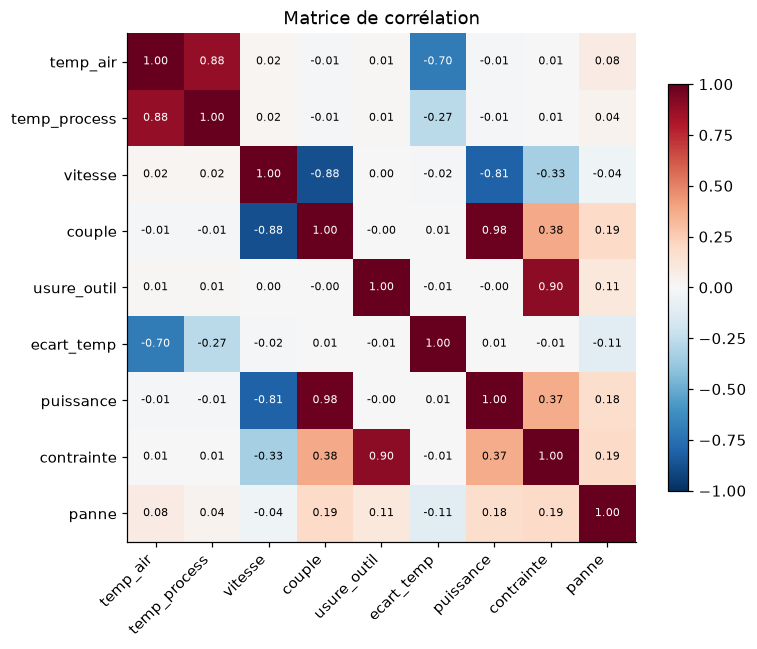

In [10]:
cols = CAPTEURS + ["ecart_temp", "puissance", "contrainte", "panne"]
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right"); ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.5 else "black")
ax.grid(False); fig.colorbar(im, shrink=0.8); ax.set_title("Matrice de corrélation")
sauver("06_correlations"); plt.show()

**Lecture** :
- Les deux températures sont très liées (0,88) : la température du procédé suit celle de l'air.
- La vitesse et le couple sont fortement liés en sens inverse (−0,88) : la machine tourne plus lentement quand l'effort augmente.
- Avec la panne, aucune corrélation n'est forte (au plus 0,19 pour le couple). Cela confirme que les pannes viennent de **seuils** et de **combinaisons**, que des modèles à base d'arbres (forêt aléatoire, gradient boosting) capturent mieux qu'un modèle linéaire.

## 9. Conclusions et décisions pour la modélisation (étape 3)

| Constat | Décision |
|---|---|
| 3,4 % de pannes (données déséquilibrées) | Évaluer avec le rappel, la précision, le F1 et la PR-AUC ; pondérer les classes ; régler le seuil d'alerte |
| Les colonnes TWF à RNF décrivent la panne | **Jamais** en entrée du modèle, uniquement comme cible |
| `UDI` et `id_produit` sont des identifiants | Exclus des entrées |
| La gamme influence le risque | Gardée en entrée (encodée) |
| Les pannes viennent de combinaisons de capteurs | Ajouter `ecart_temp`, `puissance` et `contrainte` |
| Relations par seuils, non linéaires | Comparer la régression logistique à des modèles d'arbres |
| 9 pannes sans type, 18 RNF avec `panne = 0` | `panne` reste la cible principale ; type « Indéterminé » pour les 9 cas |
| Pannes aléatoires imprévisibles | Signalées comme limite, sans chercher à les « apprendre » |
| Données synthétiques, règles exactes | Résultats à présenter avec prudence |

**Prochaine étape** : entraîner et comparer les modèles (étape 3 du cahier des charges).